In [79]:
# imports
import numpy as np
from time import perf_counter
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import loadmat
from scipy.sparse import issparse
from PIL import Image

In [25]:
# ex 1
def soft_thresholding(Y, tau):
    U, s, Vt = np.linalg.svd(Y, full_matrices=False)

    s = np.maximum(s - tau, 0)

    return U @ np.diag(s) @ Vt

def SVT(tau, delta, Omega, P_Omega_M, maxit, tol):

    Y = np.zeros_like(P_Omega_M, dtype=float)
    resvec = []

    norm_M = np.linalg.norm(P_Omega_M, "fro")

    if norm_M == 0:
        return Y, np.array([0.0])

    for k in range(maxit):
        X = soft_thresholding(Y, tau)

        R = P_Omega_M - np.where(Omega, X, 0)

        # Calculate the relative residual
        res = np.linalg.norm(R, "fro") / norm_M
        resvec.append(res)

        # Stopping criterion
        if res <= tol:
            break

        Y = Y + delta * R
    
    return X, resvec

In [26]:
M = np.array([
    [4.0, 2.0],
    [2.0, 1.0]
])

Omega = np.array([
    [True, True],
    [True, False]
])

P_Omega_M = np.where(Omega, M, 0)

X, resvec = SVT(
    tau=10,
    delta=1.2,
    Omega=Omega,
    P_Omega_M=P_Omega_M,
    maxit=1000,
    tol=1e-6
)

print("Original matrix:\n", M)
print("Observed matrix:\n", P_Omega_M)
print("Recovered matrix:\n", X)
print("Iterations:", len(resvec))
print("Final residual:", resvec[-1])

Original matrix:
 [[4. 2.]
 [2. 1.]]
Observed matrix:
 [[4. 2.]
 [2. 0.]]
Recovered matrix:
 [[4.00000231 1.99999753]
 [1.99999753 0.99999695]]
Iterations: 51
Final residual: 8.559162059652203e-07


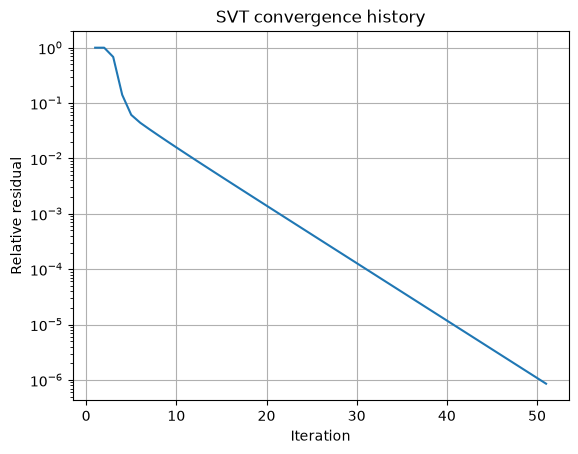

In [27]:
plt.semilogy(
    range(1, len(resvec) + 1),
    resvec
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT convergence history")
plt.grid(True)
plt.show()

In [28]:
Y = np.array([
    [4, 2],
    [2, 0]
])

tau = 3

U, s, Vt = np.linalg.svd(Y, full_matrices=False)

print("Original singular values:", s)

s = np.maximum(s - tau, 0)

print("New singular values:", s)
print("New diagonal matrix:\n", np.diag(s))

X = U @ np.diag(s) @ Vt

print("Reconstructed matrix:\n", X)

print("Original shape:", Y.shape)
print("Reconstructed shape:", X.shape)

print("Original rank:", np.linalg.matrix_rank(Y))
print("Reconstructed rank:", np.linalg.matrix_rank(X))

Original singular values: [4.82842712 0.82842712]
New singular values: [1.82842712 0.        ]
New diagonal matrix:
 [[1.82842712 0.        ]
 [0.         0.        ]]
Reconstructed matrix:
 [[1.56066017 0.64644661]
 [0.64644661 0.26776695]]
Original shape: (2, 2)
Reconstructed shape: (2, 2)
Original rank: 2
Reconstructed rank: 1


In [34]:
# ex 2
rng = np.random.default_rng(42)

n = 100
r = 3
p = 5
tau = 100

A = rng.standard_normal((n, r))
B = rng.standard_normal((r, n))

M = A @ B

print("Shape:", M.shape)
print("Rank:", np.linalg.matrix_rank(M))

Shape: (100, 100)
Rank: 3


In [ ]:
m = 2 * n * r * p

indices = rng.choice(n * n, size=m, replace=False)

Omega = np.zeros(n * n, dtype=bool)
Omega[indices] = True
Omega = Omega.reshape(n, n)

P_Omega_M = np.where(Omega, M, 0)

print("Omega shape:", Omega.shape)
print("Observed matrix shape:", P_Omega_M.shape)
print("Number of observations:", Omega.sum())
print("Observed fraction:", Omega.mean())

Omega shape: (100, 100)
Observed matrix shape: (100, 100)
Number of observations: 3000
Observed fraction: 0.3


In [36]:
delta = 1.2
maxit = 1000
tol = 1e-5

start = perf_counter()

X, resvec = SVT(
    tau, delta, Omega, P_Omega_M, maxit, tol
)

end = perf_counter()

elapsed_time = end - start

print("Iterations:", len(resvec))
print("Final residual:", resvec[-1])
print("Computational time:", elapsed_time)

Iterations: 1000
Final residual: 0.001136561851075753
Computational time: 0.8421789580006589


In [37]:
error = np.linalg.norm(M - X, "fro") / np.linalg.norm(M, "fro")

print("Reconstruction error:", error)
print("Original rank:", np.linalg.matrix_rank(M))
print("Recovered rank:", np.linalg.matrix_rank(X))

Reconstruction error: 0.18510620117251383
Original rank: 3
Recovered rank: 34


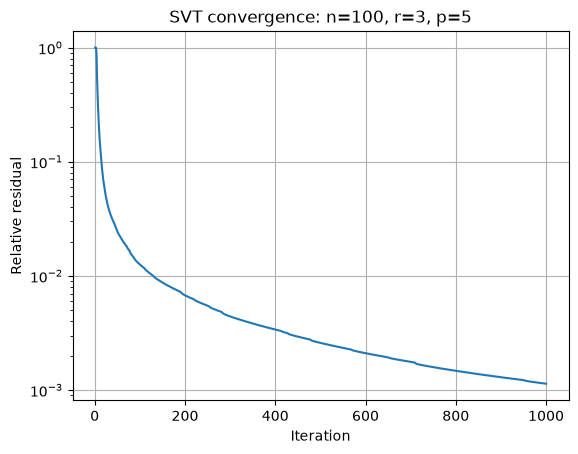

In [38]:
plt.semilogy(
    range(1, len(resvec) + 1),
    resvec
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title(f"SVT convergence: n={n}, r={r}, p={p}")
plt.grid(True)
plt.show()

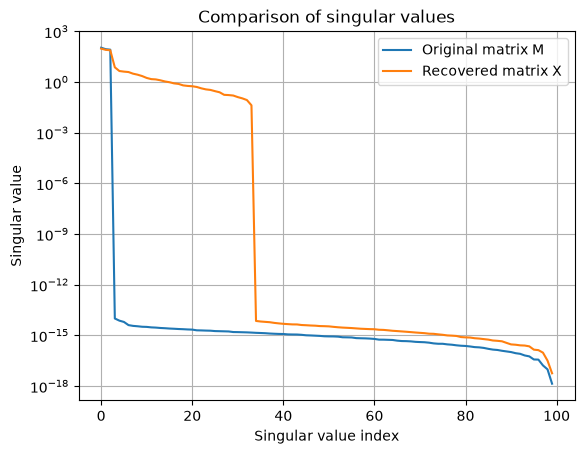

In [39]:
s_M = np.linalg.svd(M, compute_uv=False)
s_X = np.linalg.svd(X, compute_uv=False)

plt.semilogy(s_M, label="Original matrix M")
plt.semilogy(s_X, label="Recovered matrix X")

plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.title("Comparison of singular values")
plt.legend()
plt.grid(True)
plt.show()

In [44]:
n_values = [100, 200]
r_values = [3, 4, 5, 6]
p_values = [5, 7]

tau = 100
delta = 1.2
maxit = 1000
tol = 1e-5

results = []
histories = {}
matrices = {}

for n in n_values:
    for r in r_values:

        rng = np.random.default_rng(42)

        A = rng.standard_normal((n, r))
        B = rng.standard_normal((r, n))

        M = A @ B

        matrices[(n, r)] = M

        indices = rng.permutation(n * n)

        for p in p_values:

            m = 2 * n * r * p

            Omega = np.zeros(n * n, dtype=bool)
            Omega[indices[:m]] = True
            Omega = Omega.reshape(n, n)

            P_Omega_M = np.where(Omega, M, 0)

            start = perf_counter()

            X, resvec = SVT(
                tau, delta, Omega,
                P_Omega_M, maxit, tol
            )

            elapsed_time = perf_counter() - start

            error = (
                np.linalg.norm(M - X, "fro")
                / np.linalg.norm(M, "fro")
            )

            histories[(n, r, p)] = resvec

            results.append({
                "n": n,
                "r": r,
                "p": p,
                "observed_fraction": m / n**2,
                "iterations": len(resvec),
                "residual": resvec[-1],
                "error": error,
                "recovered_rank": np.linalg.matrix_rank(X),
                "time": elapsed_time,
                "converged": resvec[-1] <= tol
            })

df = pd.DataFrame(results)

display(df)

,n,r,p,observed_fraction,iterations,residual,error,recovered_rank,time,converged
0,100,3,5,0.30,1000,0.001243,0.164383,33,0.824439,False
1,100,3,7,0.42,1000,0.000246,0.060332,16,0.796061,False
2,100,4,5,0.40,1000,0.000514,0.044132,27,0.810796,False
3,100,4,7,0.56,103,0.000010,0.000021,5,0.081269,True
4,100,5,5,0.50,1000,0.000128,0.003303,15,0.801772,False
5,100,5,7,0.70,55,0.000009,0.000014,5,0.043112,True
6,100,6,5,0.60,327,0.000010,0.000044,12,0.260732,True
7,100,6,7,0.84,36,0.000008,0.000010,6,0.027870,True
8,200,3,5,0.15,1000,0.000189,0.490115,56,2.716439,False
9,200,3,7,0.21,1000,0.000355,0.330647,63,2.746438,False


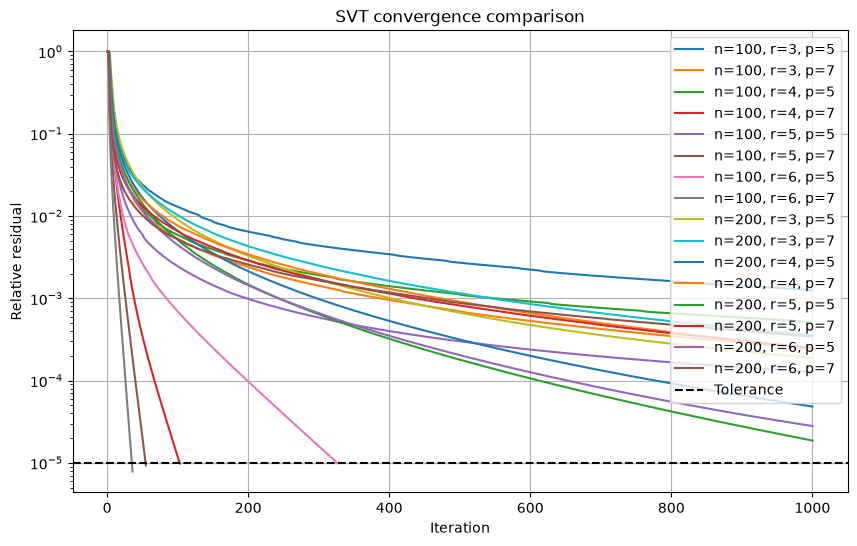

In [45]:
plt.figure(figsize=(10, 6))

for (n, r, p), resvec in histories.items():

    plt.semilogy(
        range(1, len(resvec) + 1),
        resvec,
        label=f"n={n}, r={r}, p={p}"
    )

plt.axhline(
    y=tol,
    color="black",
    linestyle="--",
    label="Tolerance"
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT convergence comparison")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
def coherence(Q):
    n, r = Q.shape

    row_norms_squared = np.sum(Q**2, axis=1)

    mu = (n / r) * np.max(row_norms_squared)

    return mu

coherence_results = []

for (n, r), M in matrices.items():

    U, s, Vt = np.linalg.svd(M, full_matrices=False)

    U_r = U[:, :r]
    V_r = Vt[:r, :].T

    mu_U = coherence(U_r)
    mu_V = coherence(V_r)

    mu_max = max(mu_U, mu_V)

    coherence_results.append({
        "n": n,
        "r": r,
        "mu_U": mu_U,
        "mu_V": mu_V,
        "mu_max": mu_max
    })

df_coherence = pd.DataFrame(coherence_results)

display(df_coherence)

,n,r,mu_U,mu_V,mu_max
0,100,3,4.526741,3.090118,4.526741
1,100,4,3.417631,4.502825,4.502825
2,100,5,3.097393,3.222963,3.222963
3,100,6,3.276432,2.959593,3.276432
4,200,3,4.841830,4.895796,4.895796
5,200,4,3.753999,3.640500,3.753999
6,200,5,4.594252,3.007257,4.594252
7,200,6,3.058517,2.877936,3.058517


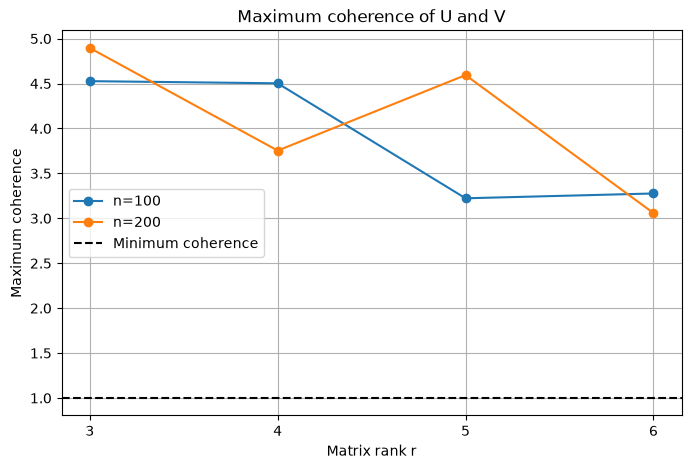

In [47]:
plt.figure(figsize=(8, 5))

for n in n_values:

    subset = df_coherence[df_coherence["n"] == n]

    plt.plot(
        subset["r"],
        subset["mu_max"],
        marker="o",
        label=f"n={n}"
    )

plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    label="Minimum coherence"
)

plt.xlabel("Matrix rank r")
plt.ylabel("Maximum coherence")
plt.title("Maximum coherence of U and V")
plt.xticks(r_values)
plt.legend()
plt.grid(True)
plt.show()

In [49]:
# Ex 3
data = loadmat("../lab2/A_med.mat")
dictionary = loadmat("../lab2/dict_med.mat")

print(data.keys())
print(dictionary.keys())

dict_keys(['__header__', '__version__', '__globals__', 'A_med'])
dict_keys(['__header__', '__version__', '__globals__', 'dict_med'])


/var/folders/sy/50gk3zw177g4529p4qy2310c0000gp/T/ipykernel_43829/3432894855.py:2: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
        That means the default return type will be a sparse array.
        Unless you use * instead of @, ** for matrix power, or you depend
        on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
        See the spmatrix to sparray migration guide for details.
        https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
        
  data = loadmat("../lab2/A_med.mat")


In [50]:
A_med = data["A_med"]
dict_med = dictionary["dict_med"]

print("Matrix shape:", A_med.shape)
print("Dictionary shape:", dict_med.shape)
print("Matrix type:", type(A_med))

Matrix shape: (5735, 1033)
Dictionary shape: (5735,)
Matrix type: <class 'scipy.sparse._csc.csc_matrix'>


In [51]:
if issparse(A_med):
    A_med = A_med.toarray()

A_med = A_med.astype(float)

In [52]:
rng = np.random.default_rng(42)

q = 0.8

n_rows, n_cols = A_med.shape

total_entries = n_rows * n_cols

m = int(q * total_entries)

print("Total entries:", total_entries)
print("Observed entries:", m)
print("Missing entries:", total_entries - m)

Total entries: 5924255
Observed entries: 4739404
Missing entries: 1184851


In [55]:
indices = rng.choice(
    total_entries,
    size=m,
    replace=False
)

Omega = np.zeros(total_entries, dtype=bool)

Omega[indices] = True

Omega = Omega.reshape(n_rows, n_cols)

P_Omega_A = np.where(Omega, A_med, 0)

print("Original shape:", A_med.shape)
print("Mask shape:", Omega.shape)
print("Observed matrix shape:", P_Omega_A.shape)
print("Observed fraction:", Omega.mean())

Original shape: (5735, 1033)
Mask shape: (5735, 1033)
Observed matrix shape: (5735, 1033)
Observed fraction: 0.8


In [56]:
tau = 10
delta = 1
maxit = 10
tol = 1e-5

start = perf_counter()

A_med2, resvec = SVT(
    tau,
    delta,
    Omega,
    P_Omega_A,
    maxit,
    tol
)

elapsed_time = perf_counter() - start

print("Iterations:", len(resvec))
print("Final residual:", resvec[-1])
print("Computational time:", elapsed_time)

Iterations: 10
Final residual: 0.0009232805304031939
Computational time: 3.624780540998472


In [57]:
print("Residual history:", resvec)

monotonic = np.all(np.diff(resvec) <= 1e-12)

print("Monotonically decreasing:", monotonic)

Residual history: [np.float64(1.0), np.float64(0.6660201754485839), np.float64(0.242230825224259), np.float64(0.09912772985387938), np.float64(0.040291386556867016), np.float64(0.016583697480022315), np.float64(0.0079721780692526), np.float64(0.0028980980540875586), np.float64(0.0013839579378049926), np.float64(0.0009232805304031939)]
Monotonically decreasing: True


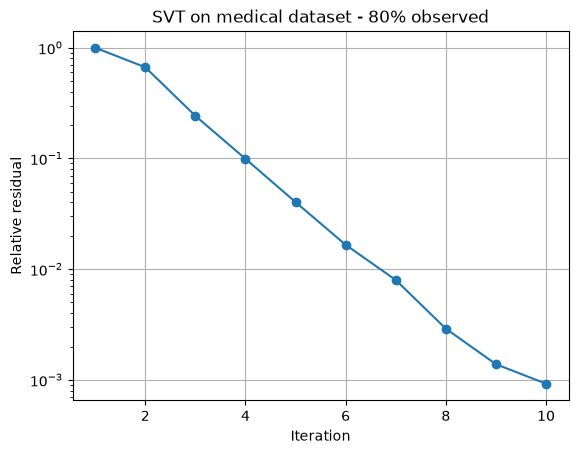

In [58]:
plt.semilogy(
    range(1, len(resvec) + 1),
    resvec,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT on medical dataset - 80% observed")
plt.grid(True)
plt.show()

In [59]:
tau = 10
delta = 1
maxit = 100
tol = 1e-5

start = perf_counter()

A_med2, resvec = SVT(
    tau, delta, Omega, P_Omega_A, maxit, tol
)

elapsed_time = perf_counter() - start

print("Iterations:", len(resvec))
print("Final residual:", resvec[-1])
print("Computational time:", elapsed_time)
print("Converged:", resvec[-1] <= tol)
print("Monotonic:", np.all(np.diff(resvec) <= 1e-12))

Iterations: 28
Final residual: 8.662666891491153e-06
Computational time: 10.318720791998203
Converged: True
Monotonic: True


In [60]:
error = (
    np.linalg.norm(A_med - A_med2, "fro")
    / np.linalg.norm(A_med, "fro")
)

print("Reconstruction error:", error)

Reconstruction error: 0.4316200591886323


In [61]:
doc_idx = 0

original_doc = A_med[:, doc_idx]
reconstructed_doc = A_med2[:, doc_idx]

print(original_doc.shape)
print(reconstructed_doc.shape)

(5735,)
(5735,)


In [64]:
reconstructed_doc = np.round(reconstructed_doc)
original_indices = np.where(original_doc > 0)[0]

reconstructed_indices = np.where(reconstructed_doc > 0)[0]

original_indices = original_indices[:10]
reconstructed_indices = reconstructed_indices[:10]

In [65]:
print(dictionary.keys())
print(dict_med.shape)
print(dict_med.dtype)
print(dict_med[:5])

dict_keys(['__header__', '__version__', '__globals__', 'dict_med'])
(5735,)
<U23
['14th                   ' '17b                    '
 '18th                   ' '19th                   '
 '1st                    ']


In [66]:
print("Original rank:", np.linalg.matrix_rank(A_med))

print("Recovered rank:", np.linalg.matrix_rank(A_med2))

Original rank: 1033
Recovered rank: 1033


In [67]:
dict_med = np.char.strip(dict_med)

doc_idx = 0

original_doc = A_med[:, doc_idx]

original_indices = np.where(original_doc > 0)[0]

for i in original_indices[:10]:
    print(dict_med[i], int(original_doc[i]))

acids 1
appears 1
coefficients 2
collected 1
correlation 3
correlations 1
delivery 3
dependent 2
determined 1
fatty 1


In [ ]:
reconstructed_doc = np.round(A_med2[:, doc_idx])

reconstructed_indices = np.where(reconstructed_doc > 0)[0]

for i in reconstructed_indices[:10]:
    print(dict_med[i], int(reconstructed_doc[i]))

acids 1
appears 1
coefficients 2
collected 1
correlations 1
delivery 3
dependent 2
determined 1
fatty 1
fetal 6


In [69]:
comparison = pd.DataFrame({
    "Original word": dict_med[original_indices[:10]],
    "Original count": original_doc[original_indices[:10]].astype(int),
    "Reconstructed word": dict_med[reconstructed_indices[:10]],
    "Reconstructed count": reconstructed_doc[reconstructed_indices[:10]].astype(int)
})

display(comparison)

,Original word,Original count,Reconstructed word,Reconstructed count
0,acids,1,acids,1
1,appears,1,appears,1
2,coefficients,2,coefficients,2
3,collected,1,collected,1
4,correlation,3,correlations,1
5,correlations,1,delivery,3
6,delivery,3,dependent,2
7,dependent,2,determined,1
8,determined,1,fatty,1
9,fatty,1,fetal,6


In [70]:
word_idx = np.where(dict_med == "correlation")[0][0]

print("Original count:", A_med[word_idx, doc_idx])
print("Observed:", Omega[word_idx, doc_idx])
print("SVT estimate:", A_med2[word_idx, doc_idx])
print("Rounded estimate:", reconstructed_doc[word_idx])

Original count: 3.0
Observed: False
SVT estimate: 0.14616844969286286
Rounded estimate: 0.0


In [71]:
q_values = [0.8, 0.5, 0.3]

reconstructions = {
    0.8: A_med2
}

histories_med = {
    0.8: resvec
}

masks_med = {
    0.8: Omega
}

results_med = [{
    "observed_fraction": 0.8,
    "iterations": len(resvec),
    "residual": resvec[-1],
    "error": error,
    "time": elapsed_time,
    "converged": resvec[-1] <= tol,
    "monotonic": np.all(np.diff(resvec) <= 1e-12)
}]

In [72]:
rng = np.random.default_rng(42)

n_rows, n_cols = A_med.shape
total_entries = A_med.size

indices = rng.permutation(np.flatnonzero(Omega.ravel()))

for q in [0.5, 0.3]:
    m = int(q * total_entries)

    Omega_q = np.zeros(total_entries, dtype=bool)
    Omega_q[indices[:m]] = True
    Omega_q = Omega_q.reshape(A_med.shape)

    P_Omega_A_q = np.where(Omega_q, A_med, 0)

    start = perf_counter()

    X_q, resvec_q = SVT(tau, delta, Omega_q, P_Omega_A_q, maxit, tol)

    elapsed = perf_counter() - start

    error_q = (
        np.linalg.norm(A_med - X_q, "fro")
        / np.linalg.norm(A_med, "fro")
    )

    reconstructions[q] = X_q
    histories_med[q] = resvec_q
    masks_med[q] = Omega_q

    results_med.append({
        "observed_fraction": q,
        "iterations": len(resvec_q),
        "residual": resvec_q[-1],
        "error": error_q,
        "time": elapsed,
        "converged": resvec_q[-1] <= tol,
        "monotonic": np.all(np.diff(resvec_q) <= 1e-12)
    })

df_med = pd.DataFrame(results_med)

display(df_med)

,observed_fraction,iterations,residual,error,time,converged,monotonic
0,0.8,28,0.000009,0.431620,10.318721,True,True
1,0.5,62,0.000010,0.699931,22.480065,True,True
2,0.3,100,0.000041,0.839251,36.731312,False,True


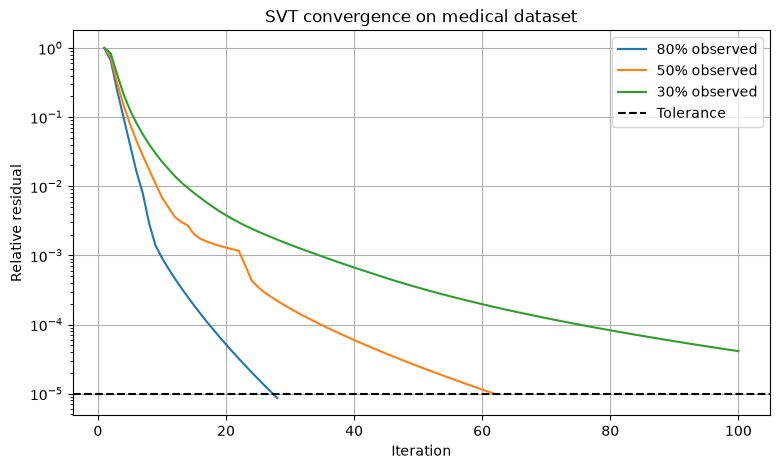

In [73]:
plt.figure(figsize=(9, 5))

for q, history in histories_med.items():

    plt.semilogy(
        range(1, len(history) + 1),
        history,
        label=f"{q:.0%} observed"
    )

plt.axhline(
    y=tol,
    color="black",
    linestyle="--",
    label="Tolerance"
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT convergence on medical dataset")
plt.legend()
plt.grid(True)
plt.show()

In [74]:
doc_idx = 0

original_doc = A_med[:, doc_idx]

original_indices = np.where(original_doc > 0)[0][:10]

comparison = pd.DataFrame({
    "Original": pd.Series(
        dict_med[original_indices]
    )
})

for q, X_q in reconstructions.items():

    reconstructed_doc = np.round(X_q[:, doc_idx])

    reconstructed_indices = np.where(
        reconstructed_doc > 0
    )[0][:10]

    comparison[f"{q:.0%} observed"] = pd.Series(
        dict_med[reconstructed_indices]
    )

display(comparison)

,Original,80% observed,50% observed,30% observed
0,acids,acids,appears,appears
1,appears,appears,coefficients,correlations
2,coefficients,coefficients,correlations,dependent
3,collected,collected,delivery,determined
4,correlation,correlations,dependent,fatty
5,correlations,delivery,determined,glucose
6,delivery,dependent,fatty,level
7,dependent,determined,glucose,maternal
8,determined,fatty,level,regression
9,fatty,fetal,lines,related


In [75]:
comparison_counts = pd.DataFrame({
    "Word": dict_med[original_indices],
    "Original count": original_doc[original_indices].astype(int)
})

for q, X_q in reconstructions.items():

    reconstructed_doc = np.round(X_q[:, doc_idx])

    comparison_counts[f"{q:.0%} observed"] = (
        reconstructed_doc[original_indices].astype(int)
    )

display(comparison_counts)

,Word,Original count,80% observed,50% observed,30% observed
0,acids,1,1,0,0
1,appears,1,1,1,1
2,coefficients,2,2,2,0
3,collected,1,1,0,0
4,correlation,3,0,0,0
5,correlations,1,1,1,1
6,delivery,3,3,3,0
7,dependent,2,2,2,2
8,determined,1,1,1,1
9,fatty,1,1,1,1


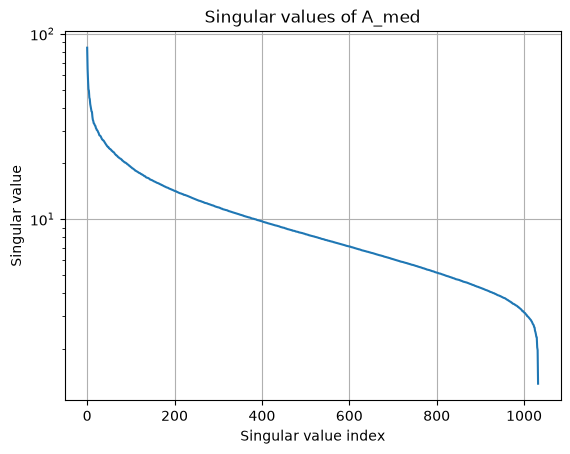

In [76]:
s = np.linalg.svd(A_med, compute_uv=False)

plt.semilogy(s)
plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.title("Singular values of A_med")
plt.grid(True)
plt.show()

In [80]:
# Ex 4
image = Image.open("DipMat.jpg").convert("RGB")

T_ten = np.array(image, dtype=float)

print("RGB tensor shape:", T_ten.shape)
print("Tensor order:", T_ten.ndim)

RGB tensor shape: (1417, 2126, 3)
Tensor order: 3


In [81]:
T_mat = np.array(
    image.convert("L"),
    dtype=float
)

print("Grayscale shape:", T_mat.shape)
print("Matrix order:", T_mat.ndim)
print("Minimum intensity:", T_mat.min())
print("Maximum intensity:", T_mat.max())

Grayscale shape: (1417, 2126)
Matrix order: 2
Minimum intensity: 0.0
Maximum intensity: 255.0


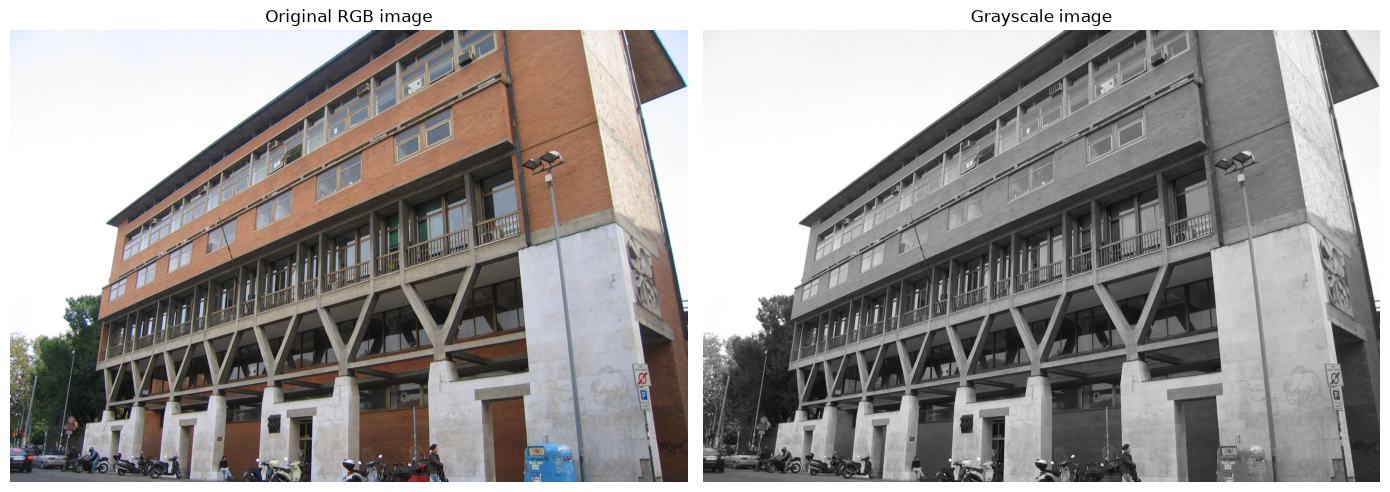

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(T_ten.astype(np.uint8))
axes[0].set_title("Original RGB image")
axes[0].axis("off")

axes[1].imshow(T_mat, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [84]:
rng = np.random.default_rng(42)

q = 0.8

n_rows, n_cols = T_mat.shape

total_entries = T_mat.size

m = int(q * total_entries)

print("Total pixels:", total_entries)
print("Observed pixels:", m)
print("Missing pixels:", total_entries - m)

Total pixels: 3012542
Observed pixels: 2410033
Missing pixels: 602509


In [86]:
indices = rng.permutation(total_entries)

Omega = np.zeros(total_entries, dtype=bool)

Omega[indices[:m]] = True

Omega = Omega.reshape(T_mat.shape)

P_Omega_A = np.where(Omega, T_mat, 0)

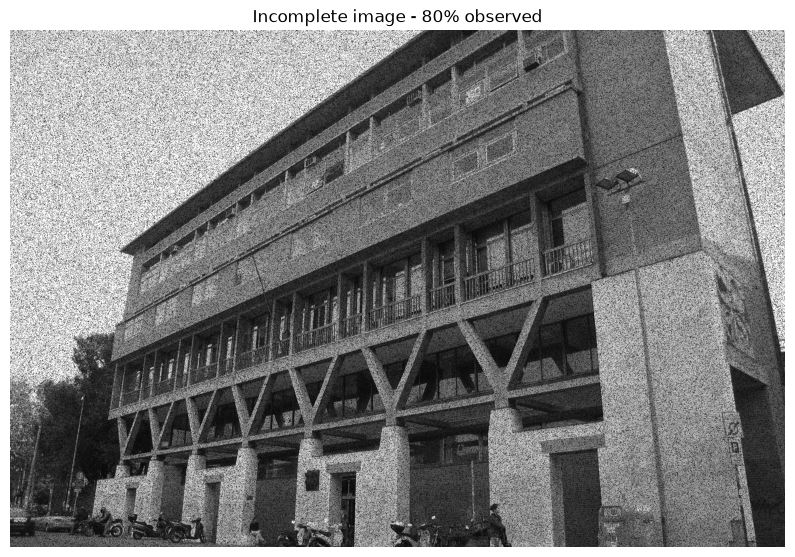

In [87]:
plt.figure(figsize=(10, 7))

plt.imshow(
    P_Omega_A,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Incomplete image - 80% observed")
plt.axis("off")
plt.show()

In [88]:
tau = 10**4
delta = 1
maxit = 10
tol = 1e-5

start = perf_counter()

DipMat2, resvec_img = SVT(
    tau,
    delta,
    Omega,
    P_Omega_A,
    maxit,
    tol
)

elapsed_time = perf_counter() - start

print("Iterations:", len(resvec_img))
print("Final residual:", resvec_img[-1])
print("Computational time:", elapsed_time)
print("Monotonic:", np.all(np.diff(resvec_img) <= 1e-12))

Iterations: 10
Final residual: 0.051233584494931574
Computational time: 4.251284499998292
Monotonic: True


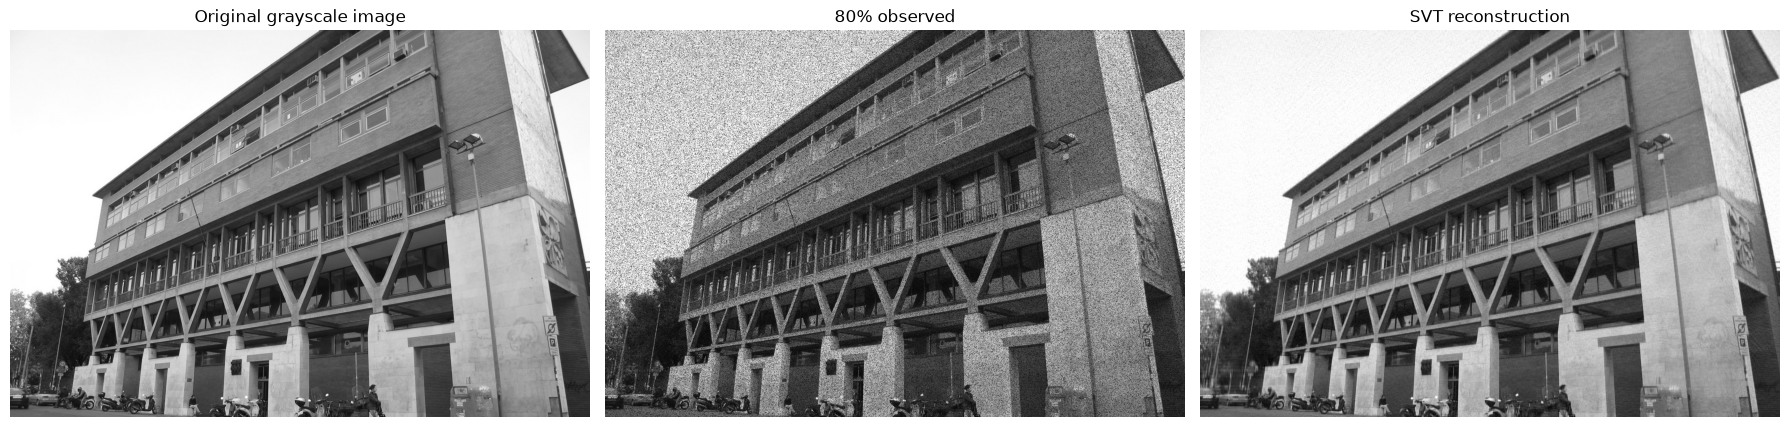

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(T_mat, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original grayscale image")

axes[1].imshow(P_Omega_A, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("80% observed")

axes[2].imshow(DipMat2, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("SVT reconstruction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [90]:
error_img = (
    np.linalg.norm(T_mat - DipMat2, "fro")
    / np.linalg.norm(T_mat, "fro")
)

print("Reconstruction error:", error_img)

Reconstruction error: 0.05697030876988277


In [91]:
error_before = (
    np.linalg.norm(T_mat - P_Omega_A, "fro")
    / np.linalg.norm(T_mat, "fro")
)

print("Error before SVT:", error_before)
print("Error after SVT:", error_img)

Error before SVT: 0.4471917966758192
Error after SVT: 0.05697030876988277


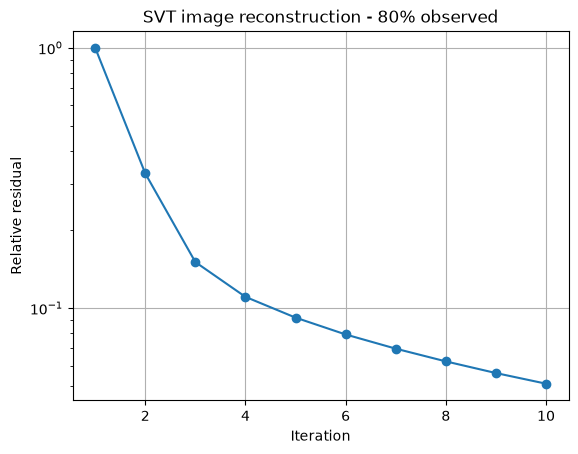

In [92]:
plt.semilogy(
    range(1, len(resvec_img) + 1),
    resvec_img,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT image reconstruction - 80% observed")
plt.grid(True)
plt.show()

In [93]:
tau = 10**4
delta = 1
maxit = 100
tol = 1e-5

start = perf_counter()

DipMat2, resvec_img = SVT(
    tau, delta, Omega,
    P_Omega_A, maxit, tol
)

elapsed_time = perf_counter() - start

error_img = (
    np.linalg.norm(T_mat - DipMat2, "fro")
    / np.linalg.norm(T_mat, "fro")
)

print("Iterations:", len(resvec_img))
print("Final residual:", resvec_img[-1])
print("Computational time:", elapsed_time)
print("Monotonic:", np.all(np.diff(resvec_img) <= 1e-12))
print("Converged:", resvec_img[-1] <= tol)
print("Reconstruction error:", error_img)

Iterations: 100
Final residual: 0.003929993407764998
Computational time: 42.69241408299786
Monotonic: True
Converged: False
Reconstruction error: 0.027535687476974085


In [94]:
q_values = [0.8, 0.5, 0.3]
tau_values = [10**4, 10**5]

reconstructions_img = {
    (0.8, 10**4): DipMat2
}

histories_img = {
    (0.8, 10**4): resvec_img
}

masks_img = {
    0.8: Omega
}

observations_img = {
    0.8: P_Omega_A
}

results_img = [{
    "q": 0.8,
    "tau": 10**4,
    "iterations": len(resvec_img),
    "residual": resvec_img[-1],
    "error": error_img,
    "time": elapsed_time,
    "converged": resvec_img[-1] <= tol,
    "monotonic": np.all(np.diff(resvec_img) <= 1e-12)
}]

In [95]:
rng = np.random.default_rng(42)

delta = 1
maxit = 100
tol = 1e-5

total_entries = T_mat.size

indices = rng.permutation(
    np.flatnonzero(Omega.ravel())
)

norm_T = np.linalg.norm(T_mat, "fro")

for q in q_values:

    # Create sampling mask
    m = int(q * total_entries)

    Omega_q = np.zeros(total_entries, dtype=bool)
    Omega_q[indices[:m]] = True
    Omega_q = Omega_q.reshape(T_mat.shape)

    # Create incomplete image
    P_Omega_A_q = np.where(Omega_q, T_mat, 0)

    masks_img[q] = Omega_q
    observations_img[q] = P_Omega_A_q

    for tau in tau_values:

        # Skip the already completed experiment
        if (q, tau) in reconstructions_img:
            continue

        start = perf_counter()

        X_q, resvec_q = SVT(
            tau, delta, Omega_q,
            P_Omega_A_q, maxit, tol
        )

        elapsed = perf_counter() - start

        error_q = (
            np.linalg.norm(T_mat - X_q, "fro")
            / norm_T
        )

        reconstructions_img[(q, tau)] = X_q
        histories_img[(q, tau)] = resvec_q

        results_img.append({
            "q": q,
            "tau": tau,
            "iterations": len(resvec_q),
            "residual": resvec_q[-1],
            "error": error_q,
            "time": elapsed,
            "converged": resvec_q[-1] <= tol,
            "monotonic": np.all(np.diff(resvec_q) <= 1e-12)
        })

        print(f"Finished q={q}, tau={tau}")

df_img = pd.DataFrame(results_img)

display(df_img)

Finished q=0.8, tau=100000
Finished q=0.5, tau=10000
Finished q=0.5, tau=100000
Finished q=0.3, tau=10000
Finished q=0.3, tau=100000


,q,tau,iterations,residual,error,time,converged,monotonic
0,0.8,10000,100,0.003930,0.027536,42.692414,False,True
1,0.8,100000,100,0.046952,0.050587,42.308988,False,True
2,0.5,10000,100,0.001585,0.163183,41.812966,False,True
3,0.5,100000,100,0.061943,0.073381,41.339167,False,True
4,0.3,10000,100,0.000336,0.390034,41.876462,False,True
5,0.3,100000,100,0.081182,0.100711,41.515931,False,True


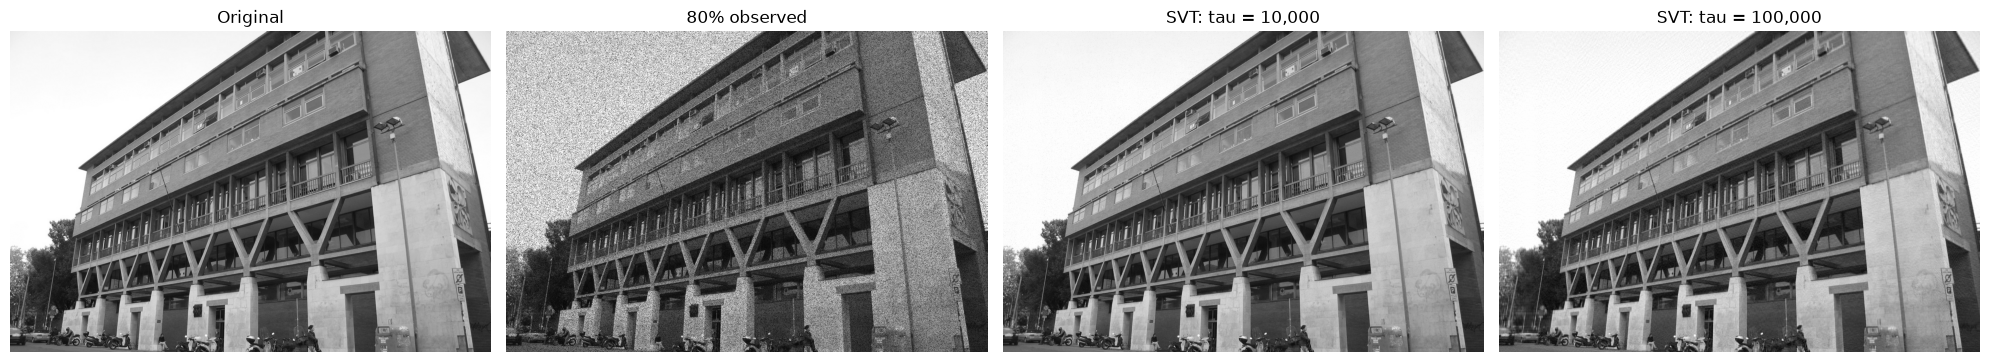

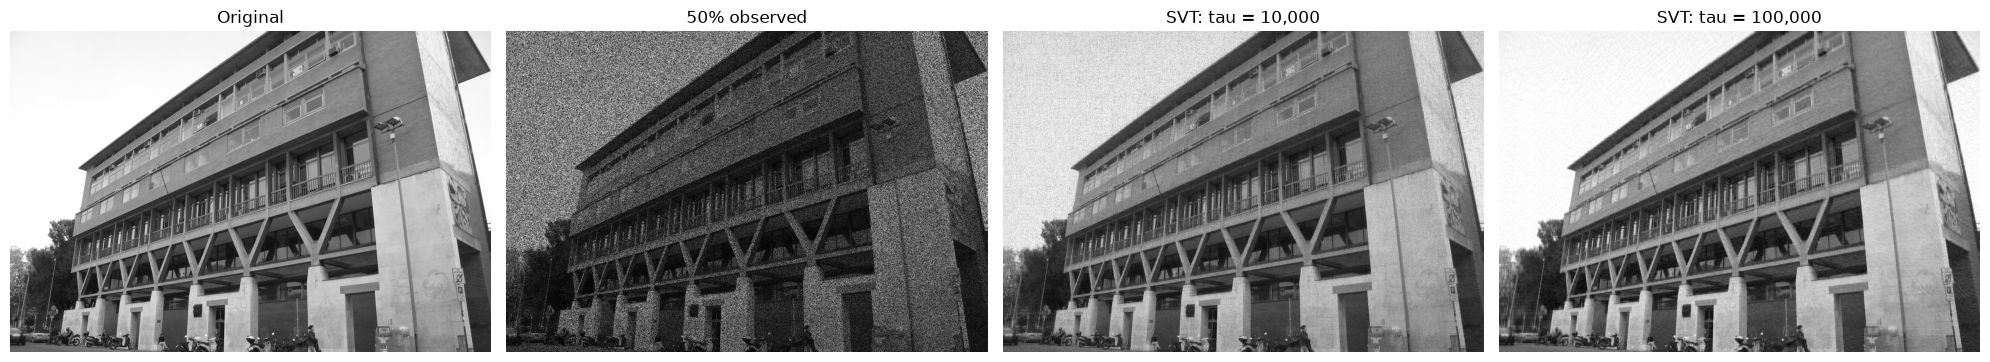

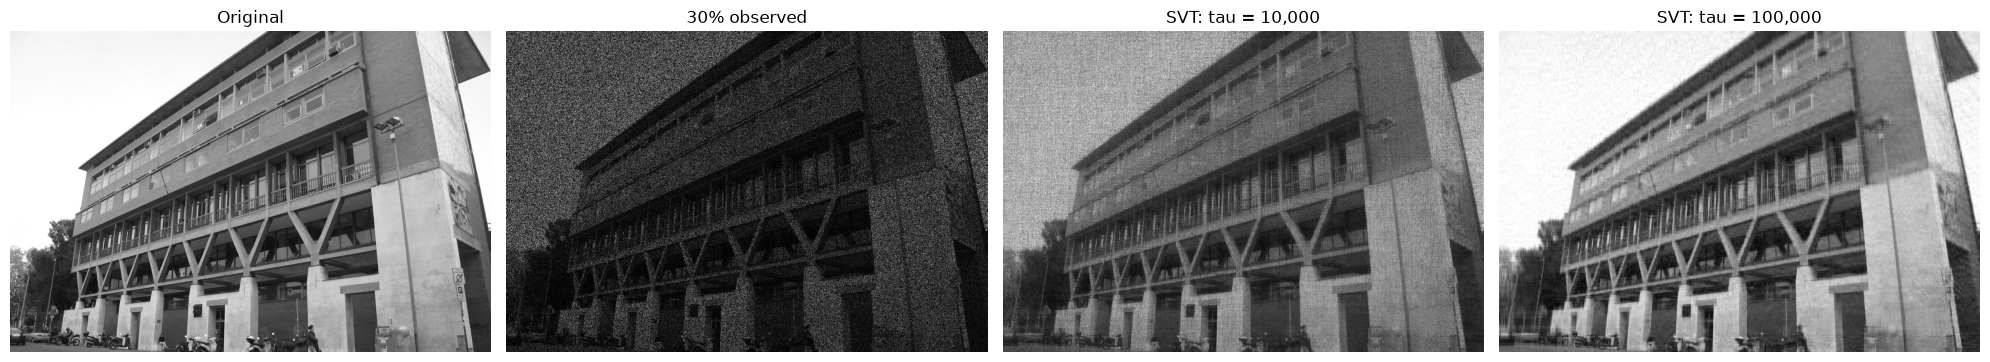

In [96]:
for q in q_values:

    fig, axes = plt.subplots(1, 4, figsize=(20, 6))

    images = [
        T_mat,
        observations_img[q],
        reconstructions_img[(q, 10**4)],
        reconstructions_img[(q, 10**5)]
    ]

    titles = [
        "Original",
        f"{q:.0%} observed",
        "SVT: tau = 10,000",
        "SVT: tau = 100,000"
    ]

    for ax, img, title in zip(axes, images, titles):

        ax.imshow(
            img,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

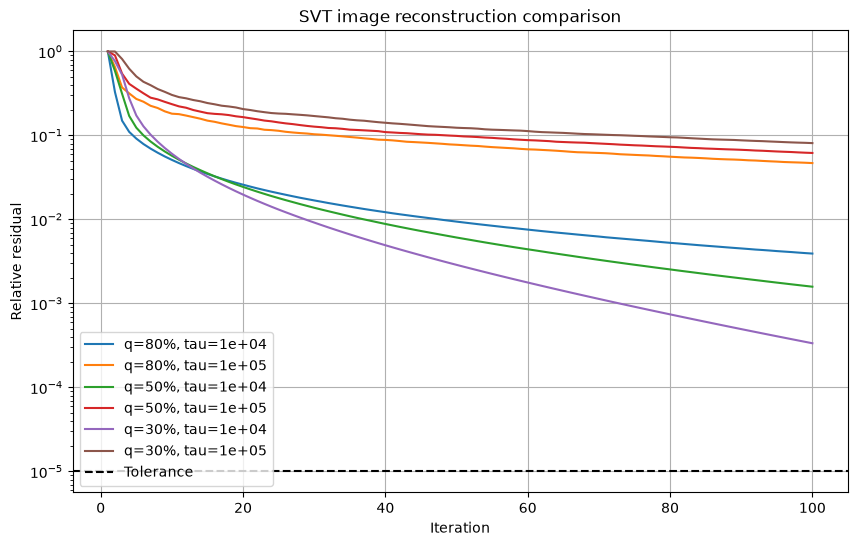

In [97]:
plt.figure(figsize=(10, 6))

for (q, tau), history in histories_img.items():

    plt.semilogy(
        range(1, len(history) + 1),
        history,
        label=f"q={q:.0%}, tau={tau:.0e}"
    )

plt.axhline(
    y=tol,
    color="black",
    linestyle="--",
    label="Tolerance"
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT image reconstruction comparison")
plt.legend()
plt.grid(True)
plt.show()